# PriViLege (CVPR 2024): reproduction on Colab

Runs the authors' code (branch `colab-fixes` of `AkilaDissanayake/PriViLege`) for the paper's results:
**Table 1** (CUB200, CIFAR-100, miniImageNet), **Tables 3 and 4** (ablations on CUB200) and **Figure 3** (PriViLege on CLIP, CIFAR-100).
Every experiment cell ends with a table of our numbers next to the paper's.

- **GPU:** A100 (or L4). A T4 (16 GB) runs out of memory at batch 128.
  VS Code: Select Kernel → Colab → **New Colab Server** → GPU. Press **Ctrl+S** after a cell finishes so its output is saved in the .ipynb.
- **Every Colab session:** run the Setup cells (1a–1e), then the experiment cell you want.
- **If Colab stops:** run Setup again and re-run the same cell. Finished runs are skipped; an interrupted run continues from its last checkpoint in Drive (`MyDrive/PriViLege/resume/`).
- Datasets download into `MyDrive/PriViLege/datasets/` the first time they are needed.

## 1. Setup

In [1]:
# 1a. Drive (keeps datasets, logs and results after the VM is wiped) and the fast local disk for training data
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE = '/content/drive/MyDrive/PriViLege'
DATA  = '/content/data'
REPO  = '/content/PriViLege'
for d in ['datasets', 'logs', 'results']:
    os.makedirs(f'{DRIVE}/{d}', exist_ok=True)
os.makedirs(DATA, exist_ok=True)
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
# 1b. Code: the colab-fixes branch (Colab patches + the CLIP and loader fixes). The commit id is logged with every result.
if not os.path.exists(REPO):
    !git clone -b colab-fixes https://github.com/AkilaDissanayake/PriViLege.git {REPO}
else:
    !git -C {REPO} pull
%cd {REPO}
COMMIT = !git rev-parse --short HEAD
COMMIT = COMMIT[0]
!git log -1 --oneline

Cloning into '/content/PriViLege'...
remote: Enumerating objects: 361, done.
remote: Counting objects: 100% (361/361), done.
remote: Compressing objects: 100% (302/302), done.
remote: Total 361 (delta 105), reused 87 (delta 37), pack-reused 0 (from 0)
Receiving objects: 100% (361/361), 2.18 MiB | 7.40 MiB/s, done.
Resolving deltas: 100% (105/105), done.
/content/PriViLege
b105633 (HEAD -> colab-fixes, origin/colab-fixes) Created using Colab


In [3]:
# 1c. Packages. Not requirements.txt (a full Anaconda dump that breaks Colab).
# timm 0.6.13 loads the same ViT-B/16 checkpoint as the authors' 0.6.12 (which fails to import on Python 3.12);
# open_clip is only needed for the CLIP experiments (Figure 3).
!pip install -q timm==0.6.13 open_clip_torch
import timm, torch, transformers, pandas, open_clip
print('timm', timm.__version__, '| torch', torch.__version__, '| transformers', transformers.__version__,
      '| pandas', pandas.__version__, '| open_clip', open_clip.__version__)
assert timm.__version__ == '0.6.13', 'Restart the session (Runtime -> Restart session / VS Code Restart) and run 1a-1c again'
assert torch.cuda.is_available(), ('No GPU: this is a CPU runtime and every run would fail. Browser: Runtime -> Change runtime '
                                   'type -> A100/L4 GPU. VS Code: Select Kernel -> Colab -> New Colab Server -> GPU.')
GPU = torch.cuda.get_device_name(0)
print('GPU:', GPU)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


timm 0.6.13 | torch 2.14.1+cu130 | transformers 5.22.1 | pandas 2.2.3 | open_clip 2.32.0
GPU: Tesla T4


In [4]:
# 1d. Datasets: copy one archive from Drive and extract it on the local disk (reading many small files from Drive is slow).
import shutil

# Google Drive file ids of the archives in the CEC folder used by FSCIL papers
# https://drive.google.com/drive/folders/11LxZCQj2FRCs0JTsf_dafvTHqFn2yGSN
GDRIVE_IDS = {
    'cub200':        '1EtKb1Bxd9ZtK-WUFk5dIhoOdhLeohA1q',   # CUB_200_2011.tgz
    'mini_imagenet': '1_x4o0iFetEv-T3PeIxdSbBPUG4hFfT8U',   # miniimagenet.tar
}
ARCHIVES = {   # dataset -> (archive in Drive, folder after extraction)
    'cifar100':      ('cifar-100-python.tar.gz', 'cifar-100-python'),
    'cub200':        ('CUB_200_2011.tgz',        'CUB_200_2011'),
    'mini_imagenet': ('miniimagenet.tar',        'miniimagenet'),
}

def prepare(dataset):
    archive, folder = ARCHIVES[dataset]
    src = f'{DRIVE}/datasets/{archive}'
    if os.path.isdir(f'{DATA}/{folder}'):
        pass
    elif os.path.exists(src):
        print(f'Extracting {archive} ...')
        get_ipython().system(f'tar -xf "{src}" -C {DATA}')
    elif dataset == 'cifar100':
        print('CIFAR-100 is not in Drive yet; train.py downloads it (copied to Drive afterwards).')
    else:
        download_to_drive(dataset)
        print(f'Extracting {archive} ...')
        get_ipython().system(f'tar -xf "{src}" -C {DATA}')
    if dataset == 'mini_imagenet' and not os.path.exists(f'{DATA}/miniimagenet/split/train.csv'):
        os.makedirs(f'{DATA}/miniimagenet/split', exist_ok=True)   # the same csv files ship with the repo
        get_ipython().system(f'cp {REPO}/data/index_list/mini_imagenet/*.csv {DATA}/miniimagenet/split/')

def download_to_drive(dataset):
    import gdown
    archive = ARCHIVES[dataset][0]
    tmp, dst = f'/content/{archive}', f'{DRIVE}/datasets/{archive}'
    print(f'{archive} is not in Drive: downloading it from the CEC Google Drive folder ...')
    gdown.download(id=GDRIVE_IDS[dataset], output=tmp, quiet=False)
    if not os.path.exists(tmp) or os.path.getsize(tmp) < 10_000_000:
        raise RuntimeError(f'Download of {archive} failed (Google Drive quota?). Try again later, or put it in '
                           f'{DRIVE}/datasets/ by hand from the CEC folder.')
    shutil.copy(tmp, dst + '.part'); os.replace(dst + '.part', dst); os.remove(tmp)
    print(f'Saved {archive} to {dst} ({os.path.getsize(dst) / 1e9:.2f} GB)')

def save_cifar_to_drive():
    src, dst = f'{DATA}/cifar-100-python.tar.gz', f'{DRIVE}/datasets/cifar-100-python.tar.gz'
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.copy(src, dst); print('Saved CIFAR-100 archive to Drive')

In [5]:
# 1e. Pretrained weights: ViT-B/16 (ImageNet-21k -> 1k AugReg, as the authors), BERT, and CLIP ViT-B/16 (LAION-2B).
# Downloads them once, so a network problem shows up now instead of mid-run.
m = timm.create_model('vit_base_patch16_224', pretrained=True)
assert 'i21k' in m.default_cfg['url'], m.default_cfg['url']
del m
from transformers import BertTokenizer, BertModel
BertTokenizer.from_pretrained('bert-base-cased'); BertModel.from_pretrained('bert-base-cased')
open_clip.create_model_and_transforms('ViT-B/16', pretrained='laion2b_s34b_b88k')
print('ViT-B/16, bert-base-cased and CLIP ViT-B/16 (LAION-2B) ready')

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

ViT-B/16, bert-base-cased and CLIP ViT-B/16 (LAION-2B) ready


## 2. Experiments, runner and paper targets

`run()` calls `train.py` with the official arguments (`run_script/vit_run_pretrain.py`) plus each experiment's flags.
It skips runs already in `MyDrive/PriViLege/results/runs.csv`, resumes interrupted runs, appends the log to Drive and records
A_Base / A_Last / A_Avg and every session's accuracy. In the comparison tables Δ = ours − paper:
green |Δ| ≤ 1, orange ≤ 3, red > 3.

In [6]:
import ast, csv, glob, json, time, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

LOG_CSV = f'{DRIVE}/results/runs.csv'
RESUME  = f'{DRIVE}/resume'
SEEDS   = [1, 2, 3, 4, 5]
VIT     = '-vit -comp_out 1'

# name -> datasets, train.py flags, epoch overrides.  Every experiment has its own name (= -out), because the
# checkpoint path does not include the -ED / -SKD / -taskblock / -ft flags.
EXP = {
    'smoke':           dict(datasets=['cifar100'], flags=f'{VIT} -LT -ED -SKD', epochs_base=1, epochs_new=1),
    # Table 1 (and the 'Ours' row of Table 3)
    'PriViLege':       dict(datasets=['cifar100', 'cub200', 'mini_imagenet'], flags=f'{VIT} -LT -ED -SKD'),
    # Table 3: Baseline = fine-tuning + prototype classifier (the released -ft option), then the PKT ablations
    'abl_Baseline':    dict(datasets=['cub200'], flags=f'{VIT} -ft'),
    'abl_PKT':         dict(datasets=['cub200'], flags=f'{VIT} -LT'),
    'abl_PKT_ED':      dict(datasets=['cub200'], flags=f'{VIT} -LT -ED'),
    'abl_PKT_SKD':     dict(datasets=['cub200'], flags=f'{VIT} -LT -SKD'),
    # Table 4: number of tuned layers, without the two losses (2 layers = abl_PKT)
    **{f'layers_{L}':  dict(datasets=['cub200'], flags=f'{VIT} -LT -taskblock {L}') for L in [0, 5, 7, 10, 12]},
    # Figure 3: CLIP ViT-B/16 (LAION-2B) on CIFAR-100. Zero-shot has no training, so one run is enough.
    'clip_zeroshot':   dict(datasets=['cifar100'], flags='-clip', epochs_base=0, seeds=[1]),
    'clip_PKT':        dict(datasets=['cifar100'], flags=f'{VIT} -pret_clip -LT'),
    'clip_PKT_ED':     dict(datasets=['cifar100'], flags=f'{VIT} -pret_clip -LT -ED'),
    'clip_PKT_ED_SKD': dict(datasets=['cifar100'], flags=f'{VIT} -pret_clip -LT -ED -SKD'),
}

def parse_results(path):
    accs = ast.literal_eval(open(path).read().strip().splitlines()[-1])   # accuracy of every session
    return accs

def finished_runs():
    if not os.path.exists(LOG_CSV):
        return {}
    with open(LOG_CSV, newline='') as f:
        return {(r['name'], r['dataset'], int(r['seed'])): r for r in csv.DictReader(f)}

def describe_state(path):
    s = json.load(open(path))
    where = (f"base epoch {s['epoch'] + 1}/{s['epochs_base']}" if s['phase'] == 'base'
             else f"session {s['session']}/{s['sessions'] - 1}")
    return f"saved after {where} at {s['saved_at']}"

def run(name, dataset, seed, force=False, batch_size=128):
    e = EXP[name]
    epochs_base, epochs_new = e.get('epochs_base', 5), e.get('epochs_new', 3)
    done = finished_runs().get((name, dataset, seed))
    ckpt = f'{RESUME}/{name}/{dataset}/seed{seed}'
    if done and not force:
        print(f"== {name} | {dataset} | seed {seed}: already finished (A_Base {done['A_Base']}, "
              f"A_Last {done['A_Last']}, A_Avg {done['A_Avg']}). Skipping.")
        return
    if force:
        shutil.rmtree(ckpt, ignore_errors=True)
    prepare(dataset)
    state_json = f'{ckpt}/resume_state.json'
    resumed = os.path.exists(state_json)
    print(f'>> {name} | {dataset} | seed {seed}: ' + (f'RESUMING, {describe_state(state_json)}' if resumed else 'starting'))
    log = f'{DRIVE}/logs/{name}_{dataset}_seed{seed}.log'
    cmd = (f'python train.py -project base -dataset {dataset} -base_mode ft_dot -new_mode avg_cos -gamma 0.1 '
           f'-lr_base 2e-4 -lr_new 2e-4 -decay 0.0005 -epochs_base {epochs_base} -epochs_new {epochs_new} '
           f'-schedule Cosine -milestones 20 30 45 -gpu 0 -temperature 16 -start_session 0 '
           f'-batch_size_base {batch_size} -seed {seed} {e["flags"]} -out {name} -dataroot {DATA} -ckpt_dir {ckpt}')
    print(cmd, '\n')
    with open(log, 'a') as f:
        f.write(f"\n===== {'resume' if resumed else 'start'} {time.strftime('%Y-%m-%d %H:%M:%S')} =====\n")
    t0 = time.time()
    get_ipython().system(f'cd {REPO} && {cmd} 2>&1 | tee -a {log}')
    minutes = (time.time() - t0) / 60
    if dataset == 'cifar100':
        save_cifar_to_drive()
    hits = sorted((p for p in glob.glob(f'{REPO}/checkpoint/**/*seed_{seed}*/results.txt', recursive=True)
                   if os.path.getmtime(p) > t0), key=os.path.getmtime)
    if not hits:
        msg = describe_state(state_json) if os.path.exists(state_json) else 'no checkpoint saved yet'
        print(f'\n!! Run stopped before finishing ({msg}). Re-run this cell to continue. Log: {log}')
        return
    dst = f'{DRIVE}/results/{name}/{dataset}/seed{seed}'
    os.makedirs(dst, exist_ok=True)
    shutil.copy(hits[-1], f'{dst}/results.txt')
    accs = parse_results(hits[-1])
    a_base, a_last, a_avg = accs[0], accs[-1], sum(accs) / len(accs)
    new_file = not os.path.exists(LOG_CSV)
    with open(LOG_CSV, 'a', newline='') as f:
        w = csv.writer(f)
        if new_file:
            w.writerow(['name', 'dataset', 'seed', 'flags', 'batch', 'gpu', 'commit', 'A_Base', 'A_Last', 'A_Avg',
                        'sessions', 'minutes', 'resumed', 'date'])
        w.writerow([name, dataset, seed, e['flags'], batch_size, GPU, COMMIT, f'{a_base:.2f}', f'{a_last:.2f}',
                    f'{a_avg:.2f}', json.dumps(accs), f'{minutes:.1f}', 'yes' if resumed else 'no',
                    time.strftime('%Y-%m-%d %H:%M')])
    shutil.rmtree(ckpt, ignore_errors=True)   # finished: free the Drive space of its resume state
    print(f'\n== {name} | {dataset} | seed {seed}: A_Base {a_base:.2f} | A_Last {a_last:.2f} | A_Avg {a_avg:.2f} | {minutes:.1f} min')

def run_all(name, datasets=None, seeds=None):
    e = EXP[name]
    for ds in datasets or e['datasets']:
        for s in seeds or e.get('seeds', SEEDS):
            run(name, ds, s)

PLAN = [(n, ds, s) for n, e in EXP.items() if n != 'smoke'
        for ds in e['datasets'] for s in e.get('seeds', SEEDS)]

def status():
    done = finished_runs()
    rows, mins = [], collections.defaultdict(list)
    for (n, ds, s), r in done.items():
        mins[(n, ds)].append(float(r['minutes']))
    for n, ds, s in PLAN:
        state_json = f'{RESUME}/{n}/{ds}/seed{s}/resume_state.json'
        state = 'done' if (n, ds, s) in done else ('resumable' if os.path.exists(state_json) else 'not started')
        rows.append((n, ds, state))
    df = pd.DataFrame(rows, columns=['experiment', 'dataset', 'state'])
    table = df.groupby(['experiment', 'dataset'], sort=False)['state'].value_counts().unstack(fill_value=0)
    display(table)
    left = [(n, ds) for n, ds, st in rows if st != 'done']
    per = {k: np.mean(v) for k, v in mins.items()}
    by_ds = collections.defaultdict(list)
    for (n, ds), v in mins.items():
        by_ds[ds] += v
    guess = [per.get(k, np.mean(by_ds[k[1]]) if by_ds[k[1]] else None) for k in left]
    est, unknown = sum(g for g in guess if g is not None), sum(g is None for g in guess)
    used = sum(sum(v) for v in mins.values())
    print(f'{len(rows) - len(left)}/{len(rows)} runs done | GPU time used {used / 60:.1f} h | '
          f'estimated time left {est / 60:.1f} h' +
          (f' + {unknown} runs on datasets with no finished run yet' if unknown else ''))

In [7]:
# Paper numbers: (mean, std) of A_Base, A_Last, A_Avg. Figure 3 has no table: those values were read off the plot
# (per session, accuracy within about +/- 0.3).
PAPER = {
    'Table 1': {('PriViLege', 'cub200'):        [(82.21, .35), (75.08, .52), (77.50, .33)],
                ('PriViLege', 'cifar100'):      [(90.88, .20), (86.06, .32), (88.08, .20)],
                ('PriViLege', 'mini_imagenet'): [(96.68, .06), (94.10, .13), (95.27, .11)]},
    'Table 3': {('abl_Baseline', 'cub200'): [(84.21, .13), (3.79, 1.47), (21.60, 1.32)],
                ('abl_PKT', 'cub200'):      [(79.06, .77), (70.81, .76), (73.36, .77)],
                ('abl_PKT_ED', 'cub200'):   [(80.31, .54), (72.70, .45), (75.04, .40)],
                ('abl_PKT_SKD', 'cub200'):  [(82.10, .57), (73.44, .40), (76.27, .30)],
                ('PriViLege', 'cub200'):    [(82.21, .35), (75.08, .52), (77.50, .33)]},
    'Table 4': {('layers_0', 'cub200'):  [(76.07, .56), (60.19, 1.11), (67.08, .71)],
                ('abl_PKT', 'cub200'):   [(79.06, .77), (70.81, .76), (73.36, .77)],
                ('layers_5', 'cub200'):  [(78.42, .84), (68.52, .84), (71.99, .84)],
                ('layers_7', 'cub200'):  [(76.96, .74), (63.15, 2.73), (68.06, 1.54)],
                ('layers_10', 'cub200'): [(74.95, .78), (57.78, 2.30), (64.19, 1.59)],
                ('layers_12', 'cub200'): [(73.62, 2.72), (56.02, 1.47), (62.71, 2.14)]},
}
FIG3 = {   # Figure 3, accuracy per session (Base, 1..8)
    'clip_zeroshot':   [78.8, 76.6, 75.2, 73.1, 72.5, 72.4, 72.7, 72.3, 71.0],
    'clip_PKT':        [82.3, 79.5, 77.6, 75.4, 74.0, 73.2, 73.3, 72.6, 71.4],
    'clip_PKT_ED':     [83.7, 81.2, 79.8, 77.6, 76.7, 76.3, 76.5, 76.2, 74.7],
    'clip_PKT_ED_SKD': [84.2, 82.1, 81.0, 79.0, 78.8, 78.4, 78.6, 78.3, 77.1],
}
PAPER['Figure 3'] = {(n, 'cifar100'): [(v[0], None), (v[-1], None), (round(float(np.mean(v)), 2), None)]
                     for n, v in FIG3.items()}
LABELS = {'PriViLege': 'PriViLege (Ours)', 'abl_Baseline': 'Baseline (fine-tune + proto)', 'abl_PKT': 'PKT',
          'abl_PKT_ED': 'PKT + L_ED', 'abl_PKT_SKD': 'PKT + L_SKD', 'layers_0': '0 layers', 'layers_5': '5 layers',
          'layers_7': '7 layers', 'layers_10': '10 layers', 'layers_12': '12 layers',
          'clip_zeroshot': 'CLIP zero-shot', 'clip_PKT': 'CLIP-PKT', 'clip_PKT_ED': 'CLIP-PKT + L_ED',
          'clip_PKT_ED_SKD': 'CLIP-PKT + L_ED + L_SKD'}
DS = {'cub200': 'CUB200', 'cifar100': 'CIFAR-100', 'mini_imagenet': 'miniImageNet'}
METRICS = ['A_Base', 'A_Last', 'A_Avg']

def runs_of(name, dataset):
    return [r for (n, ds, s), r in sorted(finished_runs().items()) if n == name and ds == dataset]

def ms(xs):
    return f'{np.mean(xs):.2f} ± {np.std(xs, ddof=1) if len(xs) > 1 else 0:.2f}'

def compare(table):
    rows = []
    for (name, ds), paper in PAPER[table].items():
        label = LABELS[name] if name != 'abl_PKT' or table != 'Table 4' else '2 layers (= PKT)'
        if table == 'Table 1':
            label = DS[ds]
        rs = runs_of(name, ds)
        row = {'': label, 'seeds': len(rs)}
        for i, m in enumerate(METRICS):
            ours = [float(r[m]) for r in rs]
            pm, ps = paper[i]
            row[f'{m} ours'] = ms(ours) if ours else '—'
            row[f'{m} paper'] = f'{pm:.2f}' + (f' ± {ps:.2f}' if ps is not None else ' (fig.)')
            row[f'Δ {m}'] = round(np.mean(ours) - pm, 2) if ours else np.nan
        rows.append(row)
    df = pd.DataFrame(rows).set_index('')
    def color(v):
        if pd.isna(v): return ''
        return 'color: green' if abs(v) <= 1 else ('color: orange' if abs(v) <= 3 else 'color: red')
    display(Markdown(f'**{table}: ours vs. paper**'))
    display(df.style.map(color, subset=[f'Δ {m}' for m in METRICS]).format(precision=2, na_rep='—'))

def plot_sessions(items, title, paper_curves=None):
    plt.figure(figsize=(7, 4))
    for i, (name, ds) in enumerate(items):
        rs = runs_of(name, ds)
        c = f'C{i}'
        label = DS[ds] if title.startswith('Table 1') else LABELS[name]
        if rs:
            acc = np.array([json.loads(r['sessions']) for r in rs])
            x = np.arange(acc.shape[1])
            plt.plot(x, acc.mean(0), '-o', color=c, ms=4, label=f'{label} (ours, n={len(rs)})')
            if len(rs) > 1:
                plt.fill_between(x, acc.mean(0) - acc.std(0, ddof=1), acc.mean(0) + acc.std(0, ddof=1), color=c, alpha=.15)
        if paper_curves and name in paper_curves:
            plt.plot(paper_curves[name], '--*', color=c, alpha=.7, label=f'{label} (paper)')
    plt.xlabel('session (0 = base)'); plt.ylabel('accuracy (%)'); plt.title(title)
    plt.grid(alpha=.3); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

def show(table):
    compare(table)
    items = list(PAPER[table])
    plot_sessions(items, f'{table}: accuracy per session', FIG3 if table == 'Figure 3' else None)

## 3. Status
What is finished, resumable or not started, GPU time used so far and an estimate of the time left.

In [8]:
status()

state                          not started
experiment      dataset                   
PriViLege       cifar100                 5
                cub200                   5
                mini_imagenet            5
abl_Baseline    cub200                   5
abl_PKT         cub200                   5
abl_PKT_ED      cub200                   5
abl_PKT_SKD     cub200                   5
layers_0        cub200                   5
layers_5        cub200                   5
layers_7        cub200                   5
layers_10       cub200                   5
layers_12       cub200                   5
clip_zeroshot   cifar100                 1
clip_PKT        cifar100                 5
clip_PKT_ED     cifar100                 5
clip_PKT_ED_SKD cifar100                 5

0/76 runs done | GPU time used 0.0 h | estimated time left 0.0 h + 76 runs on datasets with no finished run yet


## 4. Smoke test (1 base epoch + 1 epoch per session)
Catches environment, data and code problems before the long runs. It passes if the log reaches `Incremental session: [8]`
and the last line prints A_Base / A_Last / A_Avg. The numbers themselves are not meaningful.

In [9]:
run('smoke', 'cifar100', seed=1)

CIFAR-100 is not in Drive yet; train.py downloads it (copied to Drive afterwards).
>> smoke | cifar100 | seed 1: starting
python train.py -project base -dataset cifar100 -base_mode ft_dot -new_mode avg_cos -gamma 0.1 -lr_base 2e-4 -lr_new 2e-4 -decay 0.0005 -epochs_base 1 -epochs_new 1 -schedule Cosine -milestones 20 30 45 -gpu 0 -temperature 16 -start_session 0 -batch_size_base 128 -seed 1 -vit -comp_out 1 -LT -ED -SKD -out smoke -dataroot /content/data -ckpt_dir /content/drive/MyDrive/PriViLege/resume/smoke/cifar100/seed1 

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
GPU COUNT 1
Devices: [0]
Device Name: ['Tesla T4']
manual seed: 1
{'ED': True,
 'ED_hp': 0.1,
 'LT': True,
 'MP': False,
 'PKT_tune_way': 1,
 'SKD': True,
 'WC': False,
 'base_mode': 'ft_dot',
 'baseline': False,
 'batch_size_base': 128,
 'batch_size_new': 0,
 'ckpt_dir': '/content/

## 5. Table 1: PriViLege on the three benchmarks (5 seeds each)
CUB200: 100 base classes + 10 sessions of 10-way 5-shot. CIFAR-100 and miniImageNet: 60 base classes + 8 sessions of 5-way 5-shot.

>> PriViLege | cifar100 | seed 1: starting
python train.py -project base -dataset cifar100 -base_mode ft_dot -new_mode avg_cos -gamma 0.1 -lr_base 2e-4 -lr_new 2e-4 -decay 0.0005 -epochs_base 5 -epochs_new 3 -schedule Cosine -milestones 20 30 45 -gpu 0 -temperature 16 -start_session 0 -batch_size_base 128 -seed 1 -vit -comp_out 1 -LT -ED -SKD -out PriViLege -dataroot /content/data -ckpt_dir /content/drive/MyDrive/PriViLege/resume/PriViLege/cifar100/seed1 

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
GPU COUNT 1
Devices: [0]
Device Name: ['Tesla T4']
manual seed: 1
{'ED': True,
 'ED_hp': 0.1,
 'LT': True,
 'MP': False,
 'PKT_tune_way': 1,
 'SKD': True,
 'WC': False,
 'base_mode': 'ft_dot',
 'baseline': False,
 'batch_size_base': 128,
 'batch_size_new': 0,
 'ckpt_dir': '/content/drive/MyDrive/PriViLege/resume/PriViLege/cifar100/seed1',
 'clip': Fals

**Table 1: ours vs. paper**

,seeds,A_Base ours,A_Base paper,Δ A_Base,A_Last ours,A_Last paper,Δ A_Last,A_Avg ours,A_Avg paper,Δ A_Avg
,,,,,,,,,,
CUB200,0,—,82.21 ± 0.35,—,—,75.08 ± 0.52,—,—,77.50 ± 0.33,—
CIFAR-100,0,—,90.88 ± 0.20,—,—,86.06 ± 0.32,—,—,88.08 ± 0.20,—
miniImageNet,0,—,96.68 ± 0.06,—,—,94.10 ± 0.13,—,—,95.27 ± 0.11,—


/tmp/ipykernel_469/3499257790.py:78: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.grid(alpha=.3); plt.legend(fontsize=8); plt.tight_layout(); plt.show()


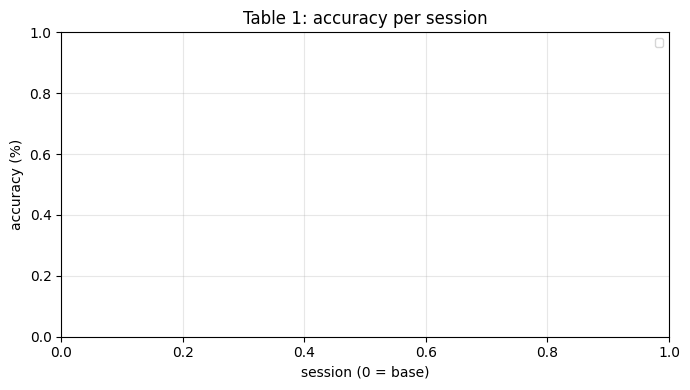

In [10]:
run_all('PriViLege', ['cifar100'])
show('Table 1')

Extracting CUB_200_2011.tgz ...
>> PriViLege | cub200 | seed 1: starting
python train.py -project base -dataset cub200 -base_mode ft_dot -new_mode avg_cos -gamma 0.1 -lr_base 2e-4 -lr_new 2e-4 -decay 0.0005 -epochs_base 5 -epochs_new 3 -schedule Cosine -milestones 20 30 45 -gpu 0 -temperature 16 -start_session 0 -batch_size_base 128 -seed 1 -vit -comp_out 1 -LT -ED -SKD -out PriViLege -dataroot /content/data -ckpt_dir /content/drive/MyDrive/PriViLege/resume/PriViLege/cub200/seed1 

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
GPU COUNT 1
Devices: [0]
Device Name: ['Tesla T4']
manual seed: 1
{'ED': True,
 'ED_hp': 0.1,
 'LT': True,
 'MP': False,
 'PKT_tune_way': 1,
 'SKD': True,
 'WC': False,
 'base_mode': 'ft_dot',
 'baseline': False,
 'batch_size_base': 128,
 'batch_size_new': 0,
 'ckpt_dir': '/content/drive/MyDrive/PriViLege/resume/PriViLege/cub2

**Table 1: ours vs. paper**

,seeds,A_Base ours,A_Base paper,Δ A_Base,A_Last ours,A_Last paper,Δ A_Last,A_Avg ours,A_Avg paper,Δ A_Avg
,,,,,,,,,,
CUB200,0,—,82.21 ± 0.35,—,—,75.08 ± 0.52,—,—,77.50 ± 0.33,—
CIFAR-100,0,—,90.88 ± 0.20,—,—,86.06 ± 0.32,—,—,88.08 ± 0.20,—
miniImageNet,0,—,96.68 ± 0.06,—,—,94.10 ± 0.13,—,—,95.27 ± 0.11,—


/tmp/ipykernel_469/3499257790.py:78: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.grid(alpha=.3); plt.legend(fontsize=8); plt.tight_layout(); plt.show()


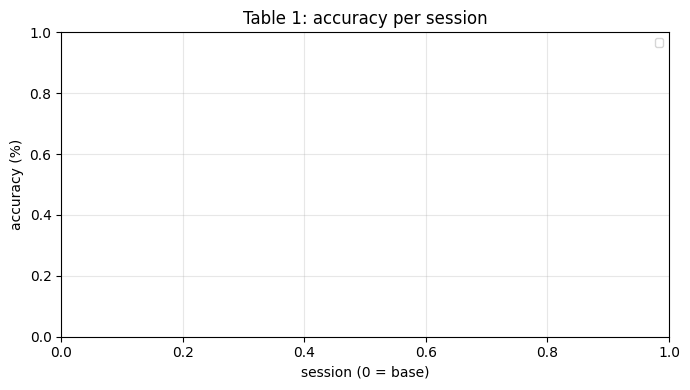

In [11]:
run_all('PriViLege', ['cub200'])
show('Table 1')

In [ ]:
run_all('PriViLege', ['mini_imagenet'])
show('Table 1')

Extracting miniimagenet.tar ...
>> PriViLege | mini_imagenet | seed 1: starting
python train.py -project base -dataset mini_imagenet -base_mode ft_dot -new_mode avg_cos -gamma 0.1 -lr_base 2e-4 -lr_new 2e-4 -decay 0.0005 -epochs_base 5 -epochs_new 3 -schedule Cosine -milestones 20 30 45 -gpu 0 -temperature 16 -start_session 0 -batch_size_base 128 -seed 1 -vit -comp_out 1 -LT -ED -SKD -out PriViLege -dataroot /content/data -ckpt_dir /content/drive/MyDrive/PriViLege/resume/PriViLege/mini_imagenet/seed1 

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
GPU COUNT 1
Devices: [0]
Device Name: ['Tesla T4']
manual seed: 1
{'ED': True,
 'ED_hp': 0.1,
 'LT': True,
 'MP': False,
 'PKT_tune_way': 1,
 'SKD': True,
 'WC': False,
 'base_mode': 'ft_dot',
 'baseline': False,
 'batch_size_base': 128,
 'batch_size_new': 0,
 'ckpt_dir': '/content/drive/MyDrive/PriViLege/

## 6. Table 3: ablation on CUB200 (5 seeds each)
- **Baseline**: fine-tuning the pre-trained ViT with the prototype classifier ψ. This uses the released `-ft` option (ViT blocks 0–1
  trained in the base session, every parameter trained in the incremental sessions). The authors' compiled "Baseline" file
  is an unfinished experiment that does not match the paper's description, so it is not used.
- **PKT**, **PKT + L_ED**, **PKT + L_SKD**: the method without one or both losses. **Ours** reuses the Table 1 CUB200 runs.

In [ ]:
for name in ['abl_Baseline', 'abl_PKT', 'abl_PKT_ED', 'abl_PKT_SKD']:
    run_all(name)
show('Table 3')

## 7. Table 4: number of tuned layers (CUB200, 5 seeds each)
Run without the two losses, as in the paper; the 2-layer row is the PKT row of Table 3. `-taskblock` sets how many of the first
ViT blocks are trained; the B-Prompt stays in blocks 0–1.

In [ ]:
for L in [0, 5, 7, 10, 12]:
    run_all(f'layers_{L}')
show('Table 4')

## 8. Figure 3: PriViLege on CLIP (CIFAR-100, 5 seeds each)
Official open_clip CLIP ViT-B/16 pre-trained on LAION-2B. Only the vision encoder is trained, with the B-Prompt and VL-Prompt added
on top of the official modules (`models/CLIP_prompt.py`); the frozen CLIP text encoder gives the class-name embeddings.
The authors did not release this code: `models/base/ViT_Network_CLIP.py` and `models/base/CLIP_*.py` were rebuilt from their
compiled files. The paper's values are read off the figure.

In [ ]:
for name in ['clip_zeroshot', 'clip_PKT', 'clip_PKT_ED', 'clip_PKT_ED_SKD']:
    run_all(name)
show('Figure 3')

## 9. All results vs. the paper

In [ ]:
for t in ['Table 1', 'Table 3', 'Table 4', 'Figure 3']:
    compare(t)

## 10. Free disk space (optional)
Each run leaves large `.pth` checkpoints on the Colab disk. Results and resume states are already in Drive, so this is safe.

In [ ]:
!find {REPO}/checkpoint -name '*.pth' -delete
!df -h /content | tail -1